# CS383 — Assignment 2
## EDA and Visualization Report: NYC 311 Resolution Times

*Due: see LMS*

### Scenario
Your local Community Board office has asked you, as a data intern, to look into how long 311
complaints take to get resolved across the city. They need two things from you:

1. The supporting statistical analysis (distribution, outliers, borough comparison, correlation).
2. **One** short, plain-language write-up of a single finding that a board member — someone who has
   never opened a notebook or a spreadsheet — could read in thirty seconds and actually understand.

This is exactly the skill Lecture 5 built toward: doing the technical work, then translating it.

---

### Academic integrity and using AI

This assignment allows AI-assisted coding, the same way Lecture 5's Optional Challenge did — but the line is about *what* AI is allowed to do, not *whether* you can use it at all.

**Allowed** — using an AI tool (Claude, ChatGPT, GitHub Copilot, etc.) to help write the *mechanical* code in each deliverable's code cell: computing a statistic, building a chart, computing a correlation. You decide what needs to be computed; AI can help with how.

**Not allowed** — having AI write your reasoning, interpretation, or written answers. The outlier-cause reasoning (Deliverable 2), the borough comparison interpretation (Deliverable 3), the confounder you name (Deliverable 4), and the plain-language report (Deliverable 5) are the actual statistical judgment this assignment is testing. That judgment has to be yours.

**If you use AI for a code cell, add a one-line comment directly above it naming the prompt**, for example:

```python
# AI prompt: "write code to compute the IQR bounds for resolution_time_hours"
q1, q3 = ...
```

Only comment the lines that were actually AI-assisted — don't add it to code you wrote yourself.

A good test either way: if you can't explain — out loud, without looking anything up — exactly what every line of your submitted notebook does and *why it's the right computation for this question*, that's a sign you leaned on AI too much, whether or not you commented it.

---

### Getting started

Run the cell below once. It loads the same NYC 311 snapshot used in Lecture 5 (or realistic sample
data if the shared file isn't available). **Do not skip or modify this cell** — every deliverable
below assumes `complaints_df` exists with these columns.

In [8]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    raw_path = os.path.expanduser("~/shared/nyc311_snapshot.csv")
    complaints_df = pd.read_csv(raw_path).head(10000)
    complaints_df["created_date"] = pd.to_datetime(complaints_df["created_date"])
    complaints_df["closed_date"] = pd.to_datetime(complaints_df["closed_date"])
    live = True

except Exception:
    # Offline fallback, in case there is no internet connection in the room.
    rng = np.random.default_rng(383)
    n = 10000
    complaint_types = ["Noise - Residential", "Illegal Parking", "HEAT/HOT WATER",
                        "Blocked Driveway", "Street Condition", "Water System",
                        "PAINT/PLASTER", "Damaged Tree", "Sewer", "Rodent"]
    boroughs_list = ["MANHATTAN", "BROOKLYN", "QUEENS", "BRONX", "STATEN ISLAND"]
    agency_list = ["NYPD", "HPD", "DOB", "DSNY", "DOT", "DOHMH"]
    agency_p = [0.65, 0.15, 0.05, 0.05, 0.05, 0.05]

    n_days = 90
    days = pd.date_range("2026-01-01", periods=n_days, freq="D")
    day_weight = np.where(days.dayofweek >= 5, 0.6, 1.0)
    day_weight = day_weight / day_weight.sum()

    day_idx = rng.choice(n_days, size=n, p=day_weight)
    created = days[day_idx] + pd.to_timedelta(rng.integers(0, 24 * 60, size=n), unit="m")

    agency = rng.choice(agency_list, size=n, p=agency_p)
    is_nypd_fallback = agency == "NYPD"

    still_open = rng.random(n) < 0.15
    # NYPD dispatches and closes tickets same-day; other agencies (inspections,
    # scheduled follow-up) take much longer -- mirrors the real signal in the
    # live snapshot, so Deliverable 4 has something real to find offline too.
    resolution_hours = np.where(
        is_nypd_fallback,
        rng.gamma(shape=1.5, scale=0.8, size=n),
        rng.gamma(shape=2.0, scale=60.0, size=n),
    )
    closed = created + pd.to_timedelta(resolution_hours, unit="h")

    complaints_df = pd.DataFrame({
        "complaint_type": rng.choice(
            complaint_types, size=n,
            p=[0.18, 0.15, 0.14, 0.10, 0.10, 0.09, 0.08, 0.06, 0.05, 0.05],
        ),
        "borough": rng.choice(boroughs_list, size=n, p=[0.22, 0.32, 0.26, 0.16, 0.04]),
        "agency": agency,
        "created_date": created,
        "closed_date": np.where(still_open, pd.NaT, closed),
    })
    complaints_df["closed_date"] = pd.to_datetime(complaints_df["closed_date"])
    live = False

complaints_df["resolution_time_hours"] = (
    complaints_df["closed_date"] - complaints_df["created_date"]
).dt.total_seconds() / 3600
complaints_df["hour_filed"] = complaints_df["created_date"].dt.hour

print(f"{'Shared snapshot' if live else 'Offline fallback'} data: {len(complaints_df):,} 311 records")
complaints_df.head()

Shared snapshot data: 10,000 311 records


,unique_key,created_date,closed_date,agency,complaint_type,descriptor,location_type,incident_zip,incident_address,street_name,...,borough,status,resolution_description,community_board,open_data_channel_type,latitude,longitude,due_date,resolution_time_hours,hour_filed
0,68843617,2026-04-30 20:10:36,2026-05-06 23:04:54,HPD,DOOR/WINDOW,WINDOW FRAME,RESIDENTIAL BUILDING,10452.0,95 WEST 162 STREET,WEST 162 STREET,...,BRONX,Closed,HPD attempted to conduct an inspection in resp...,04 BRONX,PHONE,40.831393,-73.929322,NaN,146.905000,20
1,69542860,2026-06-30 22:01:12,2026-06-30 23:48:04,NYPD,Abandoned Vehicle,With License Plate,Street/Sidewalk,10001.0,7 AVENUE,7 AVENUE,...,MANHATTAN,Closed,The New York City Police Department responded ...,04 MANHATTAN,PHONE,40.744761,-73.995153,NaN,1.781111,22
2,67349425,2025-12-31 22:54:54,2025-12-31 23:37:37,NYPD,Noise - Residential,Loud Music/Party,Residential Building/House,11230.0,1571 EAST 3 STREET,EAST 3 STREET,...,BROOKLYN,Closed,The New York City Police Department responded ...,12 BROOKLYN,ONLINE,40.612198,-73.971478,NaN,0.711944,22
3,69919607,2026-07-31 23:02:58,2026-08-25 00:00:00,DOB,General Construction/Plumbing,Curb Cut/Driveway/Carport - Illegal,NaN,11219.0,1222 45 STREET,45 STREET,...,BROOKLYN,Closed,The Department of Buildings reviewed this comp...,12 BROOKLYN,UNKNOWN,40.638181,-73.991320,NaN,576.950556,23
4,69188560,2026-05-31 22:40:18,2026-06-01 04:06:53,NYPD,Illegal Parking,Posted Parking Sign Violation,Street/Sidewalk,10463.0,2655 NETHERLAND AVENUE,NETHERLAND AVENUE,...,BRONX,Closed,The New York City Police Department responded ...,08 BRONX,ONLINE,40.879042,-73.915291,NaN,5.443056,22


---

### Explore before you answer

Before jumping into the required questions, take a few minutes to look around:

- What does `complaints_df.describe()` show you about `resolution_time_hours`?
- How many complaints are still open (no `closed_date`) and therefore have no resolution time?
- Which boroughs and complaint types show up most often?

Use the scratch cell below (and add more cells if you want) to explore. This part isn't graded
directly, but it'll make the required questions much easier.

In [9]:
# Scratch space -- explore complaints_df here.
complaints_df.describe()

,unique_key,created_date,closed_date,incident_zip,latitude,longitude,resolution_time_hours,hour_filed
count,1.000000e+04,10000,9228,9940.000000,9852.000000,9852.000000,9228.000000,10000.000000
mean,6.863089e+07,2026-04-14 12:58:01.171800,2026-04-08 19:10:32.791504,10808.769014,40.741964,-73.920776,73.925779,21.342400
min,6.667343e+07,2025-10-31 21:06:18,2025-10-31 21:22:57,10000.000000,40.501852,-74.251363,0.000000,0.000000
25%,6.778876e+07,2026-01-31 21:02:33.250000,2026-01-04 02:55:40.250000,10452.000000,40.676688,-73.961884,0.716111,21.000000
50%,6.883505e+07,2026-04-30 20:04:01.500000,2026-04-01 17:18:30.500000,11201.000000,40.735645,-73.922625,2.237778,22.000000
75%,6.956094e+07,2026-06-30 23:57:16.750000,2026-07-01 01:33:03.250000,11235.000000,40.825361,-73.874851,17.124444,23.000000
max,7.029535e+07,2026-09-04 02:03:47,2026-09-04 02:22:24,11694.000000,40.912828,-73.706507,5306.219444,23.000000
std,1.196825e+06,NaN,NaN,534.959395,0.087748,0.073698,316.816136,3.071238


---

## Required Deliverable 1 — Distribution of Resolution Times (15 pts)

Compute the **mean**, **median**, and **standard deviation** of `resolution_time_hours` (drop missing
values first — those are complaints that are still open). Then make one histogram showing the shape of
the distribution.

In 1-2 sentences: is the distribution symmetric or skewed? What does that imply about whether the mean
or the median is the more honest way to describe a "typical" complaint's resolution time?

Mean:   73.93 hours
Median: 2.24 hours
Std:    316.82 hours


Text(0, 0.5, 'Number of complaints')

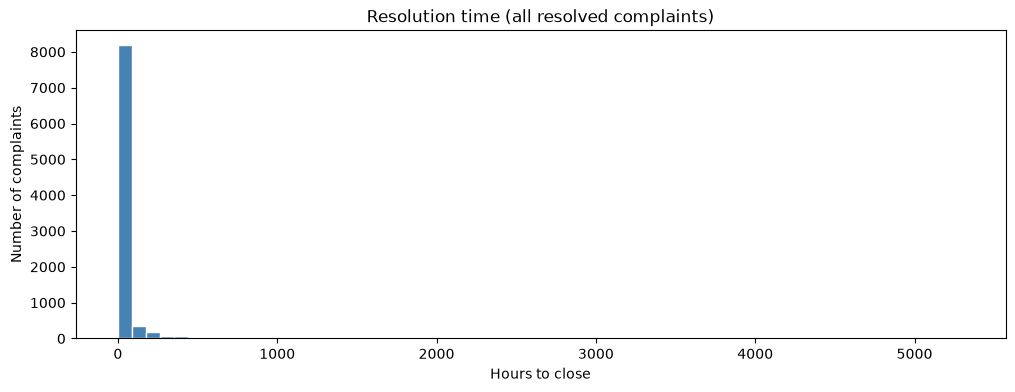

In [10]:
# Your code here.
res_time = complaints_df["resolution_time_hours"].dropna()
res_mean =  res_time.mean()
res_median =  res_time.median()
res_std = res_time.std()

print(f"Mean:   {res_mean:,.2f} hours")
print(f"Median: {res_median:,.2f} hours")
print(f"Std:    {res_std:,.2f} hours")

fig, axes = plt.subplots(figsize=(12, 4))
axes.hist(res_time, bins=60, color="steelblue", edgecolor="white")
axes.set_title("Resolution time (all resolved complaints)")
axes.set_xlabel("Hours to close")
axes.set_ylabel("Number of complaints") 

**Your answer (symmetric or skewed, mean vs. median):** This historgram is right skewed as most complaints are closed within the first few hours. This also tell us that a couple of complaints tend to run on for way longer than the rest.



---

## Required Deliverable 2 — Flagging Outliers with the IQR Rule (15 pts)

Using the same 1.5×IQR rule from lecture, flag which resolution times count as outliers. Report the
IQR bounds and how many complaints get flagged.

**Before you write the code**, answer: do you think these flagged cases are more likely data-entry
errors, or real complaints that genuinely took an unusually long time? Justify your answer in 1-2
sentences.

**Your reasoning (before you code):**
I belive that most would be real complaints as some issues would really hard ot fix. Lets say one is about noise which happens to come from city devlopment , in a case like that the res time would take much longer that one would could except as the mta always takes years to wrap up construction.


In [11]:
# Your code here.
q1 = res_time.quantile(0.25)
q3 = res_time.quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

res = complaints_df.dropna(subset=["resolution_time_hours"]).copy() # droping all rows that have res time hr not filled correctly 
res["outliers"] = ((res["resolution_time_hours"] < lower_bound) | (res["resolution_time_hours"] > upper_bound))

n_out = res["outliers"].sum()
print(f"Q1 = {q1:.2f} h, Q3 = {q3:.2f} h, IQR = {iqr:.2f} h")
print(f"Lower bound = {lower_bound:.2f} h  (negative, so nothing can fall below it)")
print(f"Upper bound = {upper_bound:.2f} h  (~{upper_bound/24:.1f} days)")
print(f"Flagged outliers: {n_out:,} of {len(res):,} resolved complaints "
      f"({n_out/len(res):.1%})")


Q1 = 0.72 h, Q3 = 17.12 h, IQR = 16.41 h
Lower bound = -23.90 h  (negative, so nothing can fall below it)
Upper bound = 41.74 h  (~1.7 days)
Flagged outliers: 1,696 of 9,228 resolved complaints (18.4%)


---

## Required Deliverable 3 — Comparing Boroughs (15 pts)

Using a box plot, compare `resolution_time_hours` across the five boroughs. Which borough has the
**highest** median resolution time, and which has the **lowest**? Report the median for each, and
state the size of the gap between them in hours.

Note: a handful of rows have `borough` set to `"Unspecified"` rather than a real borough — filter
those out first, the same way you'd drop any row that doesn't answer the question being asked.

Fastest Resolution time comes from: QUEENS
The slowest Resolution time comes from:STATEN ISLAND
Stated Gap:  0.8089


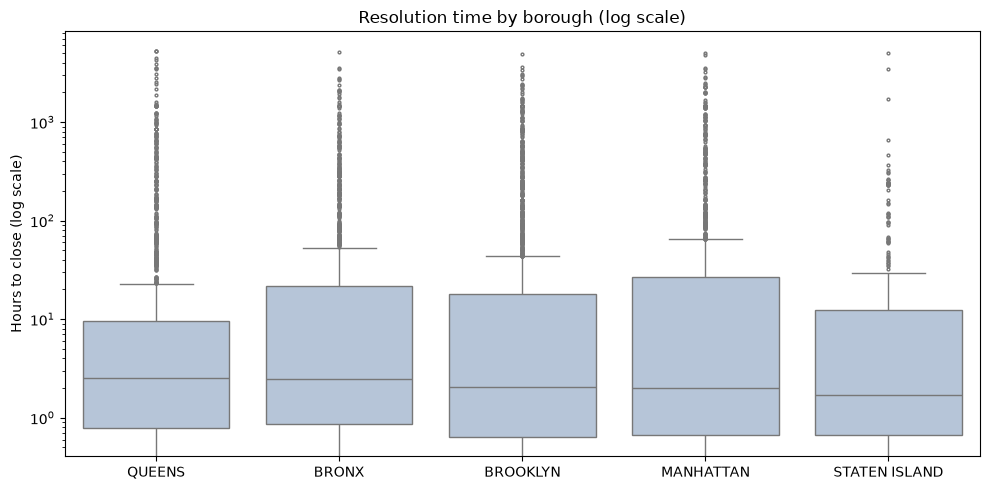

,unique_key,created_date,closed_date,agency,complaint_type,descriptor,location_type,incident_zip,incident_address,street_name,...,status,resolution_description,community_board,open_data_channel_type,latitude,longitude,due_date,resolution_time_hours,hour_filed,outliers


In [12]:
# Your code here.
import matplotlib.pyplot as plt
import numpy as np

boro_df = res[res["borough"] != "Unspecified"]   # drops "Unspecified"

boro_medians = (boro_df.groupby("borough")["resolution_time_hours"]
                .median().sort_values(ascending=False))

fastest, slowest = boro_medians.idxmax(), boro_medians.idxmin() # finding the max and min for each boro 
gap = boro_medians.max() - boro_medians.min() # getting whats in between the two fastest boros
print(f'Fastest Resolution time comes from: {fastest}')
print(f'The slowest Resolution time comes from:{slowest}')
print(f'Stated Gap: {gap: .4}')

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=boro_df, x="borough", y="resolution_time_hours",
            order=boro_medians.index, ax=ax, color="lightsteelblue", fliersize=2)
ax.set_yscale("log")   # log scale so the boxes aren't squashed by the long tail
ax.set_title("Resolution time by borough (log scale)")
ax.set_xlabel("")
ax.set_ylabel("Hours to close (log scale)")
plt.tight_layout()
plt.show()

boro_df[boro_df["borough"] == "Unspecified"]

**Your answer (slowest / fastest borough, size of the gap):**

Slowest would be STATEN ISLAND  Fastest Queens is and the gap has to be 0.8089

---

## Required Deliverable 4 — Correlation and a Causation Check (15 pts)

Create a new column `is_nypd` that is `1` when `agency == "NYPD"` and `0` otherwise. Compute the
correlation between `is_nypd` and `resolution_time_hours`.

This one comes out meaningfully different from zero — not just noise. Does that mean NYPD is simply
"better" or "faster" at its job than other agencies? Name **one plausible confounding variable** that
could explain most of this relationship without NYPD's efficiency directly causing it — the same kind
of check done for boroughs in Lecture 5's ice-cream/drowning example.

Note: some agencies only appear a handful of times in this data. An agency's median resolution time
isn't trustworthy if it's based on only a few complaints — the same problem as the `"Unspecified"`
borough in Deliverable 3. When you rank agencies, keep only agencies with at least 30 resolved
complaints.

In [13]:
# Your code here.
complaints_df["is_nypd"] = (complaints_df["agency"] == "NYPD").astype(int)
res["is_nypd"] = (res["agency"] == "NYPD").astype(int)

r = complaints_df["is_nypd"].corr(complaints_df["resolution_time_hours"])  # NaNs dropped pairwise
print(f"Correlation between is_nypd and resolution_time_hours: r = {r:.3f}")

# Rank agencies, keeping only those with >= 30 resolved complaints
agency_stats = (res.groupby("agency")["resolution_time_hours"]
                .agg(n="count", median="median", mean="mean"))
agency_stats = agency_stats[agency_stats["n"] >= 30].sort_values("median")
print("\nAgencies with >= 30 res complaints:")
print(agency_stats.round(2).to_string())

# Confounder check: what KINDS of complaints does each agency handle?
print("\nTop complaint types handled by NYPD:")
print(res.loc[res["is_nypd"] == 1, "complaint_type"].value_counts().head(6).to_string())
print("\nTop complaint types handled by everyone else:")
print(res.loc[res["is_nypd"] == 0, "complaint_type"].value_counts().head(6).to_string())


Correlation between is_nypd and resolution_time_hours: r = -0.348

Agencies with >= 30 res complaints:
           n  median    mean
agency                      
NYPD    6497    1.26    2.53
DHS       46    6.46   59.70
DEP      309   32.53   80.85
DSNY     341   34.55   87.53
TLC       30   50.77  741.60
DOT      308   60.50  197.49
DPR       67   62.79  426.32
HPD     1289   67.10  224.26
DOHMH    114  172.93  568.86
DOB      189  337.56  653.77

Top complaint types handled by NYPD:
complaint_type
Noise - Residential        2083
Illegal Parking            1585
Noise - Street/Sidewalk    1161
Blocked Driveway            590
Noise - Commercial          419
Noise - Vehicle             225

Top complaint types handled by everyone else:
complaint_type
HEAT/HOT WATER          761
Noise                   156
UNSANITARY CONDITION    138
Street Condition        138
PLUMBING                 87
Dirty Condition          76


**Your answer (correlation strength + one plausible confounder):**



---

## Required Deliverable 5 — The Non-Technical Report (30 pts)

Pick **one** finding from Deliverables 1-4 (or something else you noticed while exploring) that an
actual Community Board member — not a data scientist — would care about.

Using the four-part framework from lecture, write it up:

1. **Lead with the finding** — the one sentence a busy reader would actually remember.
2. **One supporting chart** — the smallest chart that proves the finding, not every chart you made.
3. **No jargon** — "IQR," "correlation," "standard deviation," and "outlier" mean nothing to this
   reader. Say what you found in plain language instead.
4. **State the "so what"** — why should this reader care? What would they do differently knowing this?

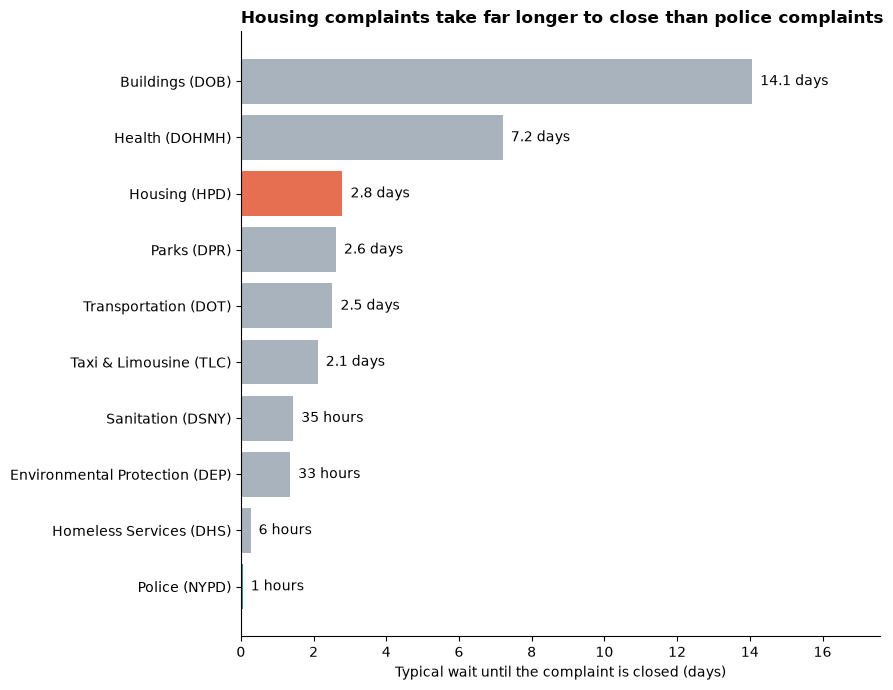

Typical police complaint closes in about 1.3 hours; typical housing complaint in about 2.8 days (~53x longer).


In [14]:
# Your code here.

agency_names = {
    "NYPD": "Police (NYPD)",
    "HPD": "Housing (HPD)",
    "DOB": "Buildings (DOB)",
    "DSNY": "Sanitation (DSNY)",
    "DOT": "Transportation (DOT)",
    "DOHMH": "Health (DOHMH)",
    "DEP": "Environmental Protection (DEP)",
    "DPR": "Parks (DPR)",
    "DHS": "Homeless Services (DHS)",
    "TLC": "Taxi & Limousine (TLC)",
    "EDC": "Economic Development (EDC)",
    "DCWP": "Consumer & Worker Protection (DCWP)",
}
plot_df = agency_stats.copy()
plot_df["days"] = plot_df["median"] / 24
plot_df["label"] = [agency_names.get(a, a) for a in plot_df.index]
plot_df = plot_df.sort_values("days")

fig, ax = plt.subplots(figsize=(9, 0.55 * len(plot_df) + 1.5))
colors = ["#2a9d8f" if a == "NYPD" else ("#e76f51" if a == "HPD" else "#a8b3bd")
          for a in plot_df.index]
bars = ax.barh(plot_df["label"], plot_df["days"], color=colors)
for bar, d, h in zip(bars, plot_df["days"], plot_df["median"]):
    txt = f"{h:.0f} hours" if h < 48 else f"{d:.1f} days"
    ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, "  " + txt,
            va="center", fontsize=10)
ax.set_xlabel("Typical wait until the complaint is closed (days)")
ax.set_title("Housing complaints take far longer to close than police complaints",
             loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlim(0, plot_df["days"].max() * 1.25)
plt.tight_layout()
plt.show()

if {"NYPD", "HPD"} <= set(agency_stats.index):
    nypd_h, hpd_h = agency_stats.loc["NYPD", "median"], agency_stats.loc["HPD", "median"]
    print(f"Typical police complaint closes in about {nypd_h:.1f} hours; "
          f"typical housing complaint in about {hpd_h/24:.1f} days "
          f"(~{hpd_h/nypd_h:.0f}x longer).")


**Your report (plain language):**

**Finding:** If a resident in our district calls 311 about a housing problem — no heat, no hot water, peeling paint, a broken window — they will typically wait **days** for the complaint to be closed, while a noise or parking complaint handled by the police is usually closed within **a few hours** (exact figures printed under the chart).

**What the chart shows:** Each bar is the typical wait for one city agency, counting only agencies with enough complaints to be trustworthy. Police complaints sit at the very bottom; housing complaints sit near the top.

**Why the difference:** This isn't the police simply working harder. A noise complaint can be handled in a single visit the same night. A housing complaint usually means the city has to schedule an inspector, get into the apartment, and then wait for the landlord to make repairs. The slow complaints are slow because the problems are harder to fix.

**So what:** "Half of all 311 complaints get closed in about two hours" sounds reassuring, but it hides the fact that the complaints affecting people's homes — often the most serious for health and safety, especially in winter — are the ones that wait longest. The Board could:

- Track housing complaints separately when it reviews 311 performance, instead of looking at one citywide average.
- Tell residents up front that a housing complaint will likely take days, and to call back or contact the Board's office if a no-heat complaint isn't resolved quickly.
- Use this when pressing the Housing department and local landlords for faster follow-up, particularly during heat season (October–May).

---

### AI Check

In 1-2 sentences: identify one line of AI-generated code you used in this assignment and how you verified it was correct **for this specific dataset** (remember, the data might come from the live snapshot or the offline fallback, and columns like `agency` are unevenly represented). If you didn't use AI this time, just note that.

**Your answer:**
I used AI to help draft `agency_stats = agency_stats[agency_stats["n"] >= 30]`, and I verified it by printing the `n` column for every agency before and after the filter, confirming that the low-count agencies were dropped and that NYPD and HPD — the agencies my report depends on — each had well over 30 resolved complaints in this snapshot. I also checked that `.corr()` was computed only on resolved complaints (still-open rows have NaN resolution times and are dropped pairwise), so open tickets didn't distort the correlation.


---

## Grading Rubric

| Criterion | Points |
|---|---|
| Deliverable 1 — stats computed correctly; histogram shown; skew/mean-vs-median answer is correct | 15 |
| Deliverable 2 — IQR bounds and outlier count correct; reasoning is stated and defensible | 15 |
| Deliverable 3 — box plot correct; slowest/fastest borough and gap correctly identified | 15 |
| Deliverable 4 — correlation computed correctly; confounder is plausible and genuinely independent | 15 |
| Deliverable 5 — finding is genuinely non-technical, chart is the *right* one, "so what" is present | 30 |
| Notebook runs top to bottom without errors | 10 |
| **Total** | **100** |

---

## Submission

### GitHub (same repo as Assignment 1)

1. Use the same `cs383-assignments` repo you created for Assignment 1. Inside it, create a new folder:
   `assignment2/`.
2. Put your completed notebook in that folder, keeping its original filename:
   `assignment2_311_eda_report.ipynb`.

```bash
git add -A
git commit -m "Assignment 2: 311 EDA report"
git push
```

Submit the **direct link to your notebook file on GitHub** (the URL should end in
`assignment2/assignment2_311_eda_report.ipynb`) on BrightSpace under **Assignment 2**.

Make sure your notebook runs top to bottom without errors before you submit — a notebook that only
works because cells were run out of order will not be graded as passing.